In [1]:
import heapq
from itertools import count

# Directed highway network from Part 1.
# Each edge is represented as: destination town -> road distance in km.
graph = {
    "Nairobi": [("Naivasha", 91), ("Thika", 47)],
    "Naivasha": [("Nakuru", 75)],
    "Thika": [("Nyeri", 113)],
    "Nyeri": [("Nakuru", 167)],
    "Nakuru": [("Eldoret", 160), ("Kericho", 107)],
    "Eldoret": [("Kisumu", 125)],
    "Kericho": [("Kisumu", 80)],
    "Kisumu": []
}


def uniform_cost_search(graph, start, goal):
    """Return the least-cost path and its cost using Uniform Cost Search."""
    tie_breaker = count()

    # Priority queue entries: (cumulative_cost, tie_breaker, current_town)
    frontier = [(0, next(tie_breaker), start)]

    # Lowest known cost from start to each town.
    best_cost = {start: 0}

    # Used to reconstruct the final path.
    parent = {start: None}

    expanded = []

    while frontier:
        current_cost, _, current_town = heapq.heappop(frontier)

        # Ignore an outdated queue entry if a cheaper route was found later.
        if current_cost != best_cost.get(current_town):
            continue

        expanded.append((current_town, current_cost))
        print(f"Expanding {current_town} (cumulative cost: {current_cost} km)")

        # UCS is optimal when the goal is removed from the priority queue.
        if current_town == goal:
            path = []
            town = goal
            while town is not None:
                path.append(town)
                town = parent[town]
            path.reverse()

            print("\nExpansion order:")
            print(" -> ".join(town for town, _ in expanded))
            print("\nOptimal path:")
            print(" -> ".join(path))
            print(f"Total path cost: {current_cost} km")

            return path, current_cost

        # Expand each outgoing directed road.
        for neighbour, road_cost in graph.get(current_town, []):
            new_cost = current_cost + road_cost

            if new_cost < best_cost.get(neighbour, float("inf")):
                best_cost[neighbour] = new_cost
                parent[neighbour] = current_town
                heapq.heappush(
                    frontier,
                    (new_cost, next(tie_breaker), neighbour)
                )
                print(
                    f"  Added/updated {neighbour} "
                    f"(path cost: {new_cost} km)"
                )

    print("No route exists between the start and goal towns.")
    return None, float("inf")


if __name__ == "__main__":
    start_town = "Nairobi"
    goal_town = "Kisumu"

    print("UNIFORM COST SEARCH: NAIROBI TO KISUMU")
    print("---------------------------------------")
    path, total_cost = uniform_cost_search(
        graph, start_town, goal_town
    )


UNIFORM COST SEARCH: NAIROBI TO KISUMU
---------------------------------------
Expanding Nairobi (cumulative cost: 0 km)
  Added/updated Naivasha (path cost: 91 km)
  Added/updated Thika (path cost: 47 km)
Expanding Thika (cumulative cost: 47 km)
  Added/updated Nyeri (path cost: 160 km)
Expanding Naivasha (cumulative cost: 91 km)
  Added/updated Nakuru (path cost: 166 km)
Expanding Nyeri (cumulative cost: 160 km)
Expanding Nakuru (cumulative cost: 166 km)
  Added/updated Eldoret (path cost: 326 km)
  Added/updated Kericho (path cost: 273 km)
Expanding Kericho (cumulative cost: 273 km)
  Added/updated Kisumu (path cost: 353 km)
Expanding Eldoret (cumulative cost: 326 km)
Expanding Kisumu (cumulative cost: 353 km)

Expansion order:
Nairobi -> Thika -> Naivasha -> Nyeri -> Nakuru -> Kericho -> Eldoret -> Kisumu

Optimal path:
Nairobi -> Naivasha -> Nakuru -> Kericho -> Kisumu
Total path cost: 353 km


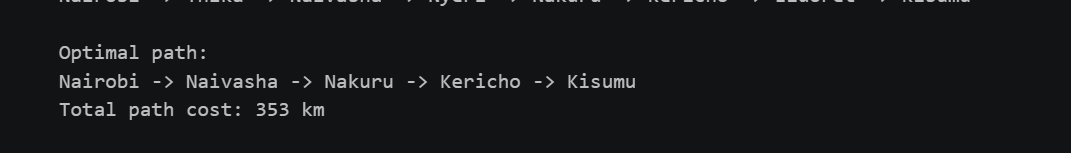

SHORT EXPLANATION DESCRIBING THE CODE

The search begins at Nairobi, which is the initial state, with a path cost of 0 km. The algorithm uses a priority queue to store the available towns according to their cumulative travel costs. At each step, it selects and expands the town with the lowest cumulative cost before exploring its connected destinations.

During the search, the trailer first explores Thika at 47 km and Naivasha at 91 km. It then explores Nyeri at 160 km, followed by Nakuru at 166 km through Naivasha. From Nakuru, the algorithm considers two possible destinations: Eldoret at 326 km and Kericho at 273 km. Since Kericho has the lower cumulative cost, it is explored first, leading to Kisumu at a total cost of 353 km.

The search terminates when Kisumu is removed from the priority queue, confirming that the least-cost path has been found.

GROUP PHOTO

![Screenshot 2026-10-16 201109.png](<attachment:Screenshot 2026-10-16 201109.png>)
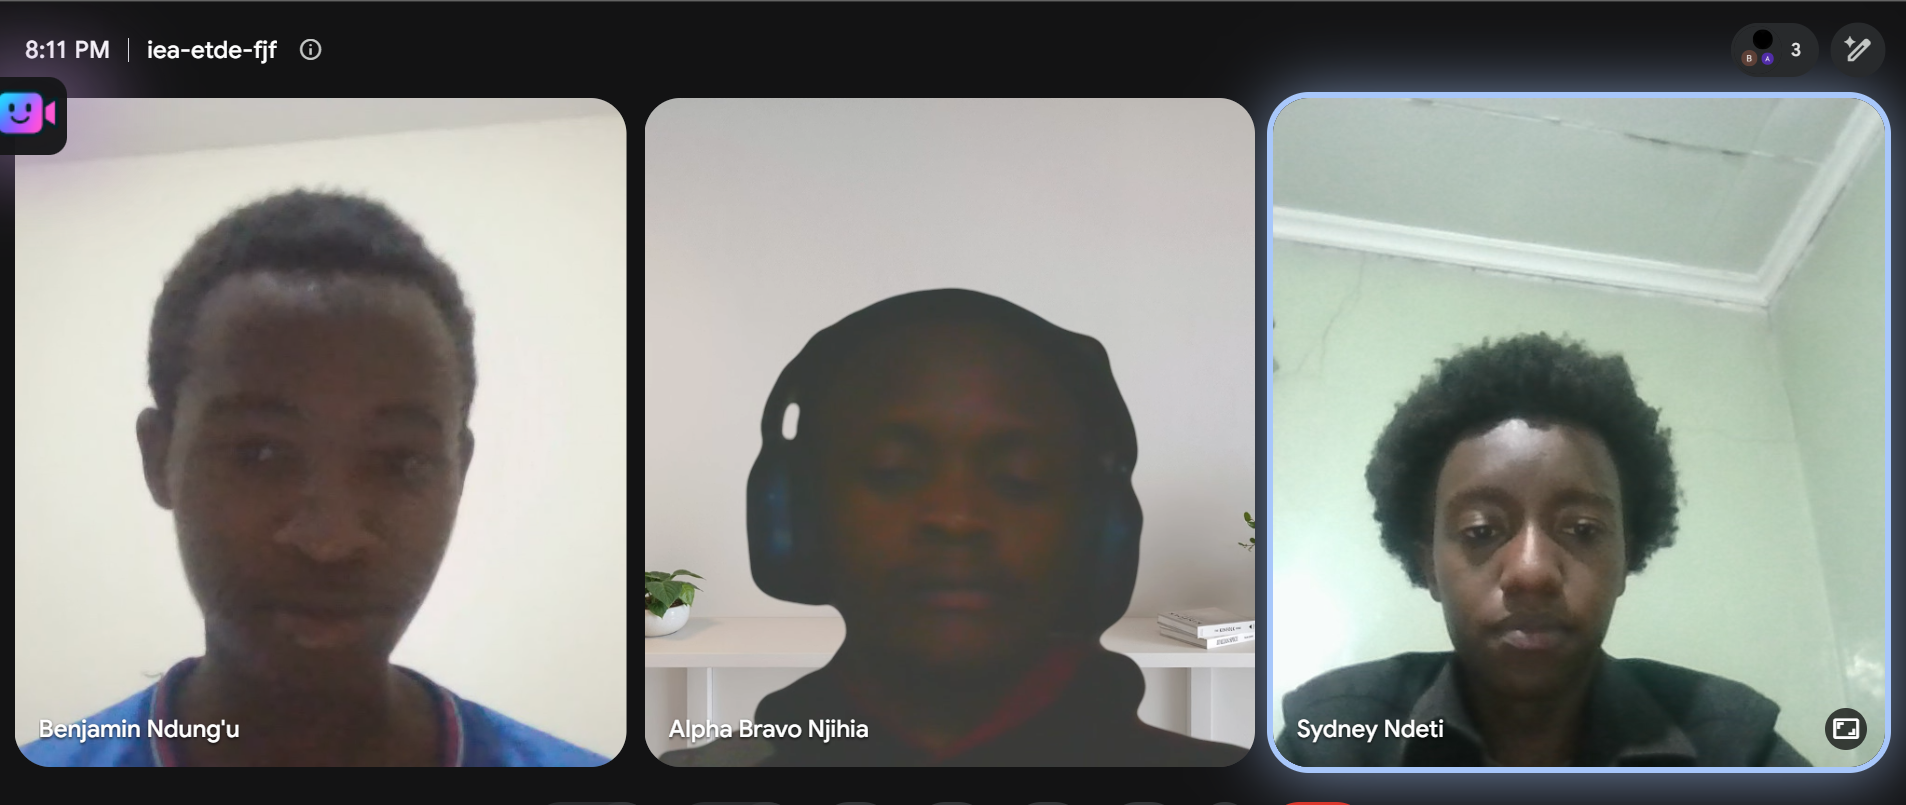